# Practice 06 — Unsupervised Learning

**Goal:** find structure in `X` alone — no label is used for fitting.

| Family | Question | Methods | Data |
|:---|:---|:---|:---|
| Clustering | which samples belong together? | Hierarchical, K-means, DBSCAN | six points, Iris, moons |
| Dimensionality reduction | can the features be compressed? | PCA, t-SNE | digits |

- Labels, where a dataset has them → used only to colour the plots

---
## Step 0. Imports

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'   # must be set before sklearn is imported

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist, squareform

from sklearn.datasets import load_iris, make_moons, load_digits
from sklearn.cluster import AgglomerativeClustering, KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, silhouette_samples

np.random.seed(42)
plt.rcParams['axes.unicode_minus'] = False

---
## Step 1. Six Points, Worked by Hand

- Six points in 2-D, small enough to follow every step on paper → each printed number can be checked by hand
- The same points for every method: hierarchical clustering, K-means, then DBSCAN

### Distances between All Pairs

- Euclidean distance between every two points → the numbers every method below starts from

In [2]:
X_six = np.array([[0, 2], [4, 5], [1, 2], [3, 9], [5, 6], [10, 9]])    # points 1 to 6

distance_six = squareform(pdist(X_six))    # 6 x 6 matrix, row i and column j = distance between points i and j
display(pd.DataFrame(distance_six, index=range(1, 7), columns=range(1, 7)).round(2))

,1,2,3,4,5,6
1,0.00,5.00,1.00,7.62,6.40,12.21
2,5.00,0.00,4.24,4.12,1.41,7.21
3,1.00,4.24,0.00,7.28,5.66,11.40
4,7.62,4.12,7.28,0.00,3.61,7.00
5,6.40,1.41,5.66,3.61,0.00,5.83
6,12.21,7.21,11.40,7.00,5.83,0.00


### Hierarchical Clustering, Single Linkage

- Each point starts as its own cluster → merge the two closest → repeat
- Merge history = **dendrogram** → cutting it at a height gives the clusters
- `fcluster` → `criterion='distance'`: cut at height `t`; `criterion='maxclust'`: cut so that `t` clusters remain

[[0.   2.   1.   2.  ]
 [1.   4.   1.41 2.  ]
 [3.   7.   3.61 3.  ]
 [6.   8.   4.24 5.  ]
 [5.   9.   5.83 6.  ]]
cut at 2.5 : [1 2 1 3 2 4]
2 clusters : [1 1 1 1 1 2]


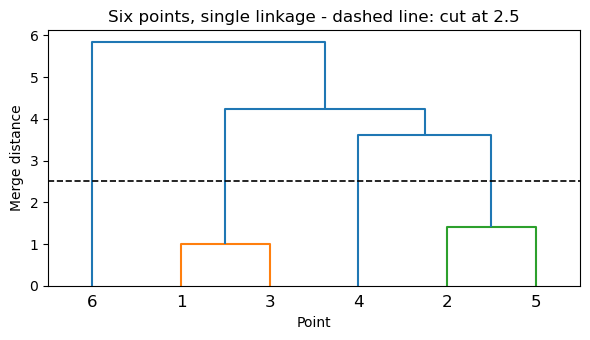

In [3]:
Z_single = linkage(X_six, method='single')
print(Z_single.round(2))
print('cut at 2.5 :', fcluster(Z_single, t=2.5, criterion='distance'))
print('2 clusters :', fcluster(Z_single, t=2, criterion='maxclust'))

plt.figure(figsize=(6, 3.5))
dendrogram(Z_single, labels=[1, 2, 3, 4, 5, 6], color_threshold=2.5)
plt.axhline(2.5, color='black', linestyle='--', linewidth=1.2)
plt.xlabel('Point')
plt.ylabel('Merge distance')
plt.title('Six points, single linkage - dashed line: cut at 2.5')
plt.tight_layout()
plt.show()

| `Z`, one row per merge | Meaning |
|:---|:---|
| columns 1, 2 | the merged clusters: 0 to 5 = points 1 to 6; 6 = the cluster made in row 1, 7 in row 2, … |
| column 3 | merge height: 1.00, 1.41, 3.61, 4.24, 5.83 |
| column 4 | size of the new cluster |

- Row 3 `[3, 7, 3.61]` → point 4 joins {2,5}
- Cut at 2.5 → {1,3}, {2,5}, {4}, {6} (coloured links); two clusters → point 6 alone

### Four Linkages, Two Clusters

| `method` | Distance between two clusters |
|:---|:---|
| `single` | closest pair of points |
| `complete` | farthest pair |
| `average` | average over all pairs |
| `ward` | grows with the increase in within-cluster sum of squares |

single   : [1 1 1 1 1 2]
complete : [1 2 1 2 2 2]
average  : [1 1 1 1 1 2]
ward     : [1 2 1 2 2 2]


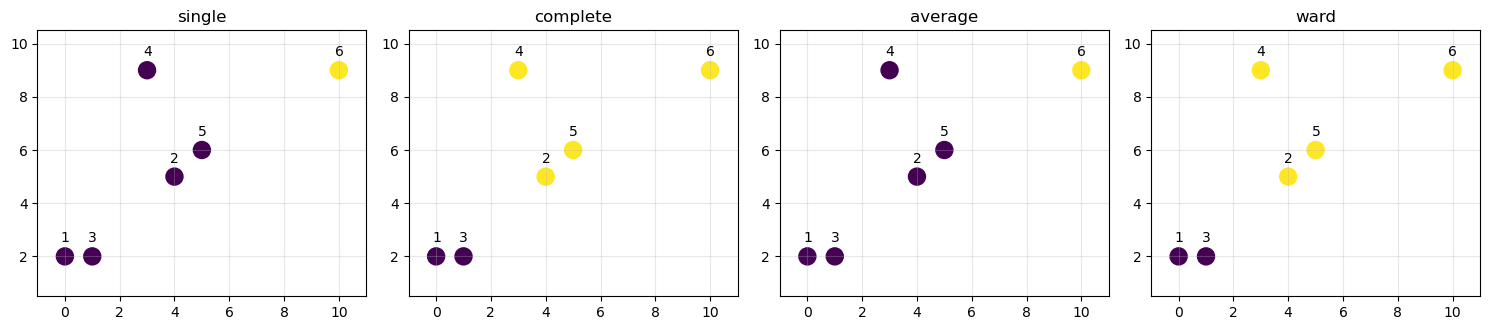

In [4]:
Z_complete = linkage(X_six, method='complete')
Z_average = linkage(X_six, method='average')
Z_ward = linkage(X_six, method='ward')

labels_single = fcluster(Z_single, t=2, criterion='maxclust')
labels_complete = fcluster(Z_complete, t=2, criterion='maxclust')
labels_average = fcluster(Z_average, t=2, criterion='maxclust')
labels_ward = fcluster(Z_ward, t=2, criterion='maxclust')

print('single   :', labels_single)
print('complete :', labels_complete)
print('average  :', labels_average)
print('ward     :', labels_ward)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
axes[0].scatter(X_six[:, 0], X_six[:, 1], c=labels_single, cmap='viridis', s=150)
axes[0].set_title('single')
axes[1].scatter(X_six[:, 0], X_six[:, 1], c=labels_complete, cmap='viridis', s=150)
axes[1].set_title('complete')
axes[2].scatter(X_six[:, 0], X_six[:, 1], c=labels_average, cmap='viridis', s=150)
axes[2].set_title('average')
axes[3].scatter(X_six[:, 0], X_six[:, 1], c=labels_ward, cmap='viridis', s=150)
axes[3].set_title('ward')

for ax in axes:
    for k in range(6):
        ax.annotate(str(k + 1), X_six[k], xytext=(-3, 10), textcoords='offset points')    # point number
    ax.set_xlim(-1, 11)
    ax.set_ylim(0.5, 10.5)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Single and average → point 6 alone; complete and ward → {1,3} apart from {2,4,5,6}
- Same data, different cluster distance → a different split

### K-means from Two Different Starts

- Place $k$ centres → assign each point to the nearest → move each centre to the mean of its points → repeat until no point changes cluster
- Where it stops depends on the starting centres

| Argument / attribute | Meaning |
|:---|:---|
| `init=X_six[[0, 2]]` | start at rows 0 and 2 = points 1 and 3 (Python counts from 0) |
| `n_init=1` | that one start only |
| `inertia_` | WSS, the sum of squared distances to the own centre |
| `n_iter_` | assignment passes |

start 1, 3 : [0 1 0 1 1 1] WSS 42.25, 3 passes
start 2, 5 : [0 0 0 1 1 1] WSS 46.67, 2 passes
10 starts  : [1 0 1 0 0 0] WSS 42.25


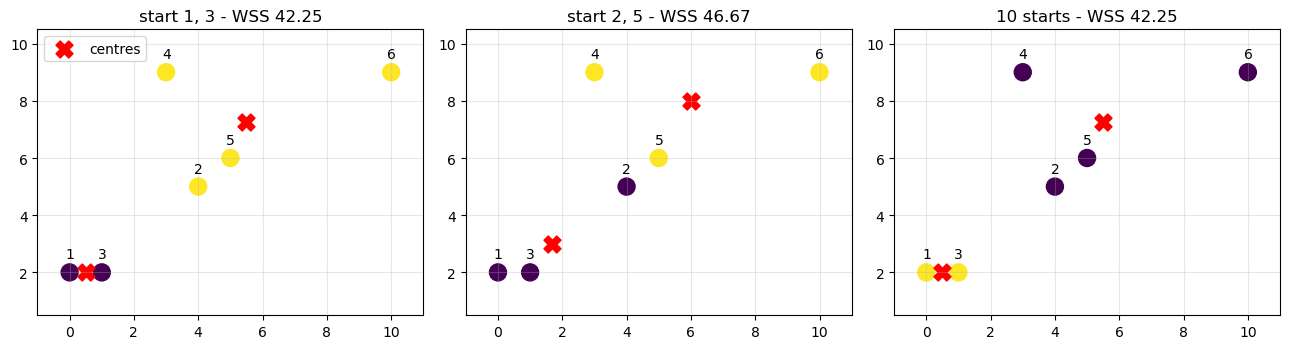

In [5]:
kmeans1 = KMeans(n_clusters=2, init=X_six[[0, 2]], n_init=1)    # start at points 1 and 3
kmeans1.fit(X_six)

kmeans2 = KMeans(n_clusters=2, init=X_six[[1, 4]], n_init=1)    # start at points 2 and 5
kmeans2.fit(X_six)

kmeans3 = KMeans(n_clusters=2, n_init=10, random_state=42)      # ten k-means++ starts, the lowest WSS is kept
kmeans3.fit(X_six)

print('start 1, 3 :', kmeans1.labels_, f'WSS {kmeans1.inertia_:.2f}, {kmeans1.n_iter_} passes')
print('start 2, 5 :', kmeans2.labels_, f'WSS {kmeans2.inertia_:.2f}, {kmeans2.n_iter_} passes')
print('10 starts  :', kmeans3.labels_, f'WSS {kmeans3.inertia_:.2f}')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].scatter(X_six[:, 0], X_six[:, 1], c=kmeans1.labels_, cmap='viridis', s=150)
axes[0].scatter(kmeans1.cluster_centers_[:, 0], kmeans1.cluster_centers_[:, 1], c='red', marker='X', s=150, label='centres')
axes[0].set_title(f'start 1, 3 - WSS {kmeans1.inertia_:.2f}')
axes[1].scatter(X_six[:, 0], X_six[:, 1], c=kmeans2.labels_, cmap='viridis', s=150)
axes[1].scatter(kmeans2.cluster_centers_[:, 0], kmeans2.cluster_centers_[:, 1], c='red', marker='X', s=150, label='centres')
axes[1].set_title(f'start 2, 5 - WSS {kmeans2.inertia_:.2f}')
axes[2].scatter(X_six[:, 0], X_six[:, 1], c=kmeans3.labels_, cmap='viridis', s=150)
axes[2].scatter(kmeans3.cluster_centers_[:, 0], kmeans3.cluster_centers_[:, 1], c='red', marker='X', s=150, label='centres')
axes[2].set_title(f'10 starts - WSS {kmeans3.inertia_:.2f}')

for ax in axes:
    for k in range(6):
        ax.annotate(str(k + 1), X_six[k], xytext=(-3, 10), textcoords='offset points')    # point number
    ax.set_xlim(-1, 11)
    ax.set_ylim(0.5, 10.5)
    ax.grid(alpha=0.3)
axes[0].legend()

plt.tight_layout()
plt.show()

| Start | Split | WSS |
|:---|:---|:---|
| points 1 and 3 | {1,3} and {2,4,5,6} | 42.25, after 3 passes |
| points 2 and 5 | {1,2,3} and {4,5,6} | 46.67, after 2 passes |
| ten starts | {1,3} and {2,4,5,6} (label numbers swapped) | 42.25 |

- Start at points 2 and 5 → K-means stopped at a worse split
- 42.25 = the lowest WSS of all 31 ways to split six points in two, and the split complete and ward found

### DBSCAN on the Same Points

| Term | Meaning |
|:---|:---|
| core point | at least `min_samples` points within `eps`, itself included |
| cluster | core points within `eps` of each other link up; each linked group gets a number 0, 1, 2, … |
| border point | not a core point, but within `eps` of one → joins that core point's cluster |
| noise | neither → label `-1`, in no cluster |

- Two settings: `eps=3.7, min_samples=2` (the one worked on the slides) and `eps=4.5, min_samples=3`; the distances to check them are in the matrix above

eps 3.7, labels      : [ 0  1  0  1  1 -1]
eps 4.5, labels      : [ 0  0  0  0  0 -1]
eps 4.5, core points : [2 3 4 5]


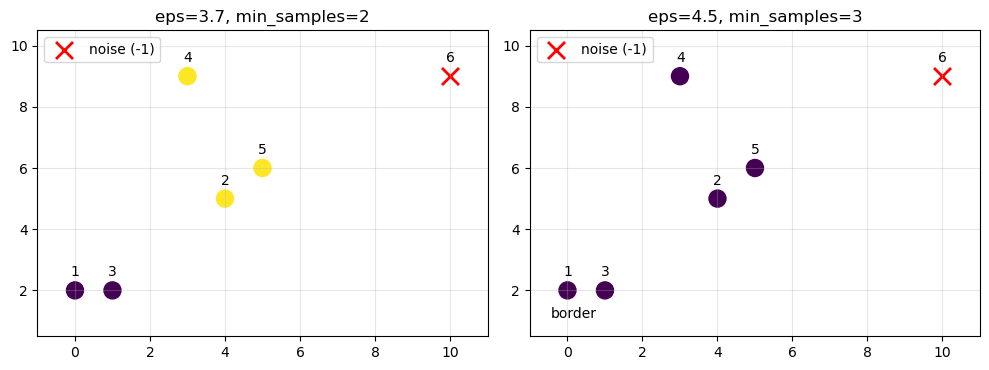

In [6]:
dbscan1 = DBSCAN(eps=3.7, min_samples=2)
dbscan1.fit(X_six)

dbscan2 = DBSCAN(eps=4.5, min_samples=3)
dbscan2.fit(X_six)

print('eps 3.7, labels      :', dbscan1.labels_)
print('eps 4.5, labels      :', dbscan2.labels_)
print('eps 4.5, core points :', dbscan2.core_sample_indices_ + 1)    # + 1: Python counts from 0, the points from 1

is_noise1 = dbscan1.labels_ == -1
is_noise2 = dbscan2.labels_ == -1

# vmin, vmax: cluster 0 and cluster 1 get the same colours in both panels

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(X_six[~is_noise1, 0], X_six[~is_noise1, 1], c=dbscan1.labels_[~is_noise1], cmap='viridis', vmin=0, vmax=1, s=150)
axes[0].scatter(X_six[is_noise1, 0], X_six[is_noise1, 1], c='red', marker='x', s=150, linewidths=2, label='noise (-1)')
axes[0].set_title('eps=3.7, min_samples=2')
axes[1].scatter(X_six[~is_noise2, 0], X_six[~is_noise2, 1], c=dbscan2.labels_[~is_noise2], cmap='viridis', vmin=0, vmax=1, s=150)
axes[1].scatter(X_six[is_noise2, 0], X_six[is_noise2, 1], c='red', marker='x', s=150, linewidths=2, label='noise (-1)')
axes[1].set_title('eps=4.5, min_samples=3')
axes[1].annotate('border', X_six[0], xytext=(-12, -20), textcoords='offset points')

for ax in axes:
    for k in range(6):
        ax.annotate(str(k + 1), X_six[k], xytext=(-3, 10), textcoords='offset points')    # point number
    ax.set_xlim(-1, 11)
    ax.set_ylim(0.5, 10.5)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

| Setting | Result |
|:---|:---|
| `eps=3.7, min_samples=2` | {1,3} → `0`; {2,4,5} → `1`, point 4 through point 5 (4 is 4.12 from 2); point 6 → `-1` |
| `eps=4.5, min_samples=3` | core points 2–5 reach each other → one cluster `0`; point 1 joins as a border point; point 6 → `-1` |

- `-1` is not a cluster → DBSCAN can leave points out, which hierarchical clustering and K-means never do

---
## Step 2. Iris — Features Only

- Iris → 150 flowers of three species, 4 measurements each; the species label is not used
- No train/test split → clustering only describes the given set
- All four features are lengths in **cm** → used as measured
- Features in different units → standardize first, or the feature with the largest numbers dominates every distance

In [7]:
iris = load_iris()
X = iris.data      # features only

print(f'X: {X.shape}')
display(pd.DataFrame(X, columns=iris.feature_names).head(10))

X: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
5,5.4,3.9,1.7,0.4
6,4.6,3.4,1.4,0.3
7,5.0,3.4,1.5,0.2
8,4.4,2.9,1.4,0.2
9,4.9,3.1,1.5,0.1


### Petal Length vs. Petal Width

- All plots below use these two axes; the algorithms use all four features

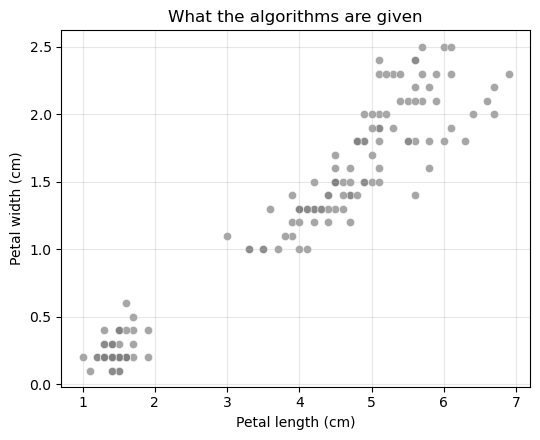

In [8]:
plt.figure(figsize=(5.5, 4.5))
plt.scatter(X[:, 2], X[:, 3], c='gray', s=35, alpha=0.7, edgecolors='white', linewidths=0.5)
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.title('What the algorithms are given')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- Two groups are obvious → is the upper-right one a single group or two?

---
## Step 3. Hierarchical Clustering on Iris

- Ward linkage (the default of `AgglomerativeClustering`) on all four features; 150 leaves, so the leaf labels are left out

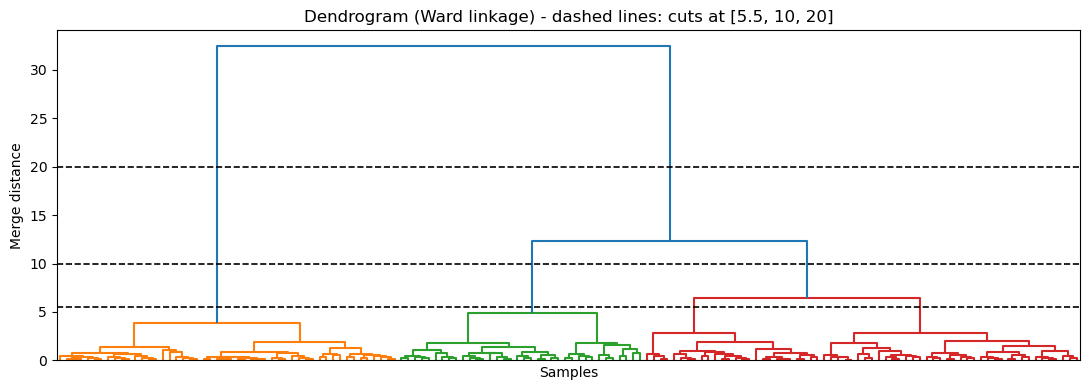

In [9]:
Z = linkage(X, method='ward')

cut_heights = [5.5, 10, 20]

plt.figure(figsize=(11, 4))
dendrogram(Z, no_labels=True, color_threshold=10)
for height in cut_heights:
    plt.axhline(height, color='black', linestyle='--', linewidth=1.2)
plt.xlabel('Samples')
plt.ylabel('Merge distance')
plt.title(f'Dendrogram (Ward linkage) - dashed lines: cuts at {cut_heights}')
plt.tight_layout()
plt.show()

- Clusters at a cut = vertical lines the cut crosses → 4 at 5.5, 3 at 10, 2 at 20
- Colours = the three clusters below the cut at 10

### Cutting the Tree at Three Heights

- The same `fcluster(..., criterion='distance')` as for the six points, at 5.5, 10 and 20

cut at 5.5 -> 4 clusters, sizes [50 36 26 38]
cut at 10 -> 3 clusters, sizes [50 36 64]
cut at 20 -> 2 clusters, sizes [ 50 100]


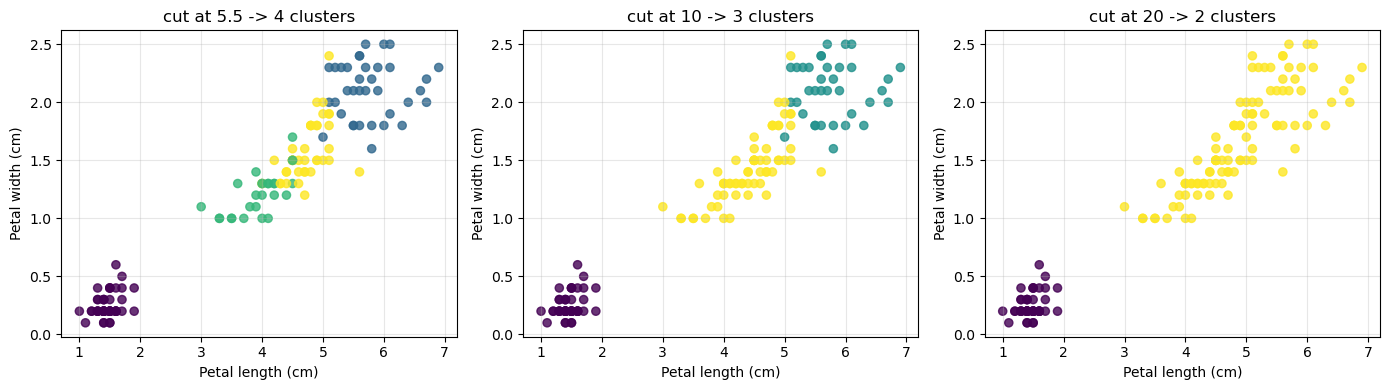

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, height in zip(axes, cut_heights):
    labels_at_height = fcluster(Z, height, criterion='distance')                # cut the tree at this height
    n_clusters = labels_at_height.max()                                         # fcluster numbers clusters 1, 2, ...
    sizes = np.bincount(labels_at_height)[1:]                                   # samples per cluster (label 0 is unused)
    print(f'cut at {height} -> {n_clusters} clusters, sizes {sizes}')

    ax.scatter(X[:, 2], X[:, 3], c=labels_at_height, cmap='viridis', s=35, alpha=0.8)
    ax.set_xlabel('Petal length (cm)')
    ax.set_ylabel('Petal width (cm)')
    ax.set_title(f'cut at {height} -> {n_clusters} clusters')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Cut 20 → 10 → 5.5: the upper-right group splits 100 → 36 + 64 → 36 + 26 + 38
- The lower-left 50 never splits

### Asking for a Number of Clusters

- `AgglomerativeClustering(n_clusters=3)` → the same Ward merges, stopped at 3 clusters

cluster sizes: [64 50 36]


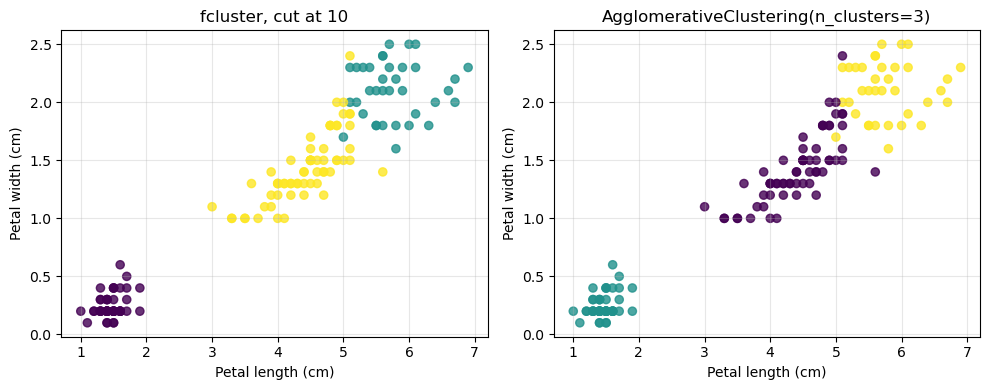

In [11]:
hierarchical = AgglomerativeClustering(n_clusters=3, linkage='ward')
hierarchical_labels = hierarchical.fit_predict(X)

print('cluster sizes:', np.bincount(hierarchical_labels))

labels_at_10 = fcluster(Z, 10, criterion='distance')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X[:, 2], X[:, 3], c=labels_at_10, cmap='viridis', s=35, alpha=0.8)
axes[0].set_title('fcluster, cut at 10')
axes[1].scatter(X[:, 2], X[:, 3], c=hierarchical_labels, cmap='viridis', s=35, alpha=0.8)
axes[1].set_title('AgglomerativeClustering(n_clusters=3)')

for ax in axes:
    ax.set_xlabel('Petal length (cm)')
    ax.set_ylabel('Petal width (cm)')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Sizes 64 / 50 / 36 → the same three groups as the cut at 10
- Only the label numbers differ, so the same group gets a different colour

---
## Step 4. K-means, and Choosing $k$

- On Iris the number of clusters is not given → fit $k$ = 1 to 9 and compare two indices

### Choosing $k$

$$\text{WSS} = \sum_{j=1}^{k} \sum_{\mathbf{x} \in C_j} \lVert \mathbf{x} - \boldsymbol{\mu}_j \rVert^2,
\qquad s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}$$

| Index | Reading |
|:---|:---|
| Inertia (WSS) | always falls as $k$ grows → look for the **elbow** |
| Silhouette (mean of $s(i)$) | −1 to 1, higher = better separated → take the **maximum** |

- $C_j$, $\boldsymbol{\mu}_j$ = cluster $j$ and its centre
- $a(i)$, $b(i)$ = mean distance from sample $i$ to its own cluster, to the nearest other

k = 1   inertia =  681.4   silhouette = nan
k = 2   inertia =  152.3   silhouette = 0.6810
k = 3   inertia =   78.9   silhouette = 0.5528
k = 4   inertia =   57.2   silhouette = 0.4981
k = 5   inertia =   46.5   silhouette = 0.4912
k = 6   inertia =   39.0   silhouette = 0.3648
k = 7   inertia =   34.3   silhouette = 0.3543
k = 8   inertia =   30.1   silhouette = 0.3487
k = 9   inertia =   28.3   silhouette = 0.3125


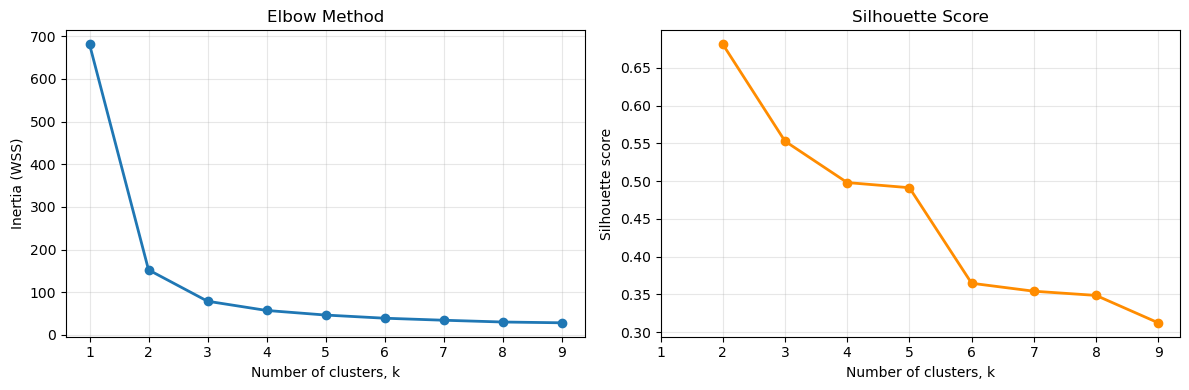

In [12]:
k_values = range(1, 10)
inertia_values = []
silhouette_values = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X)
    inertia = kmeans.inertia_
    if k == 1:
        silhouette = np.nan      # the silhouette needs at least two clusters
    else:
        silhouette = silhouette_score(X, kmeans.labels_)
    inertia_values.append(inertia)
    silhouette_values.append(silhouette)
    print(f'k = {k}   inertia = {inertia:6.1f}   silhouette = {silhouette:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertia_values, 'o-', linewidth=2)
axes[0].set_xlabel('Number of clusters, k')
axes[0].set_ylabel('Inertia (WSS)')
axes[0].set_title('Elbow Method')
axes[0].set_xticks(list(k_values))
axes[0].grid(alpha=0.3)

axes[1].plot(list(k_values), silhouette_values, 'o-', linewidth=2, color='darkorange')
axes[1].set_xlabel('Number of clusters, k')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette Score')
axes[1].set_xticks(list(k_values))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Inertia 681 → 152 → 79 → 57: the sharpest bend at $k = 2$, a smaller one at $k = 3$, flat after that
- Silhouette → highest at $k = 2$ (0.68, vs 0.55 at $k = 3$): the upper-right group has no gap, so splitting it lowers the score

### K-means with $k = 3$

- The data alone favours $k = 2$; the three species suggest $k = 3$, which also has a visible bend → used below

cluster sizes: [62 50 38]
inertia      : 78.85


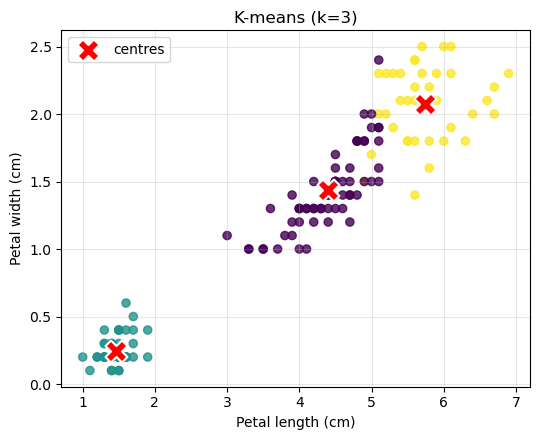

In [13]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X)
centers = kmeans.cluster_centers_

print('cluster sizes:', np.bincount(kmeans_labels))
print(f'inertia      : {kmeans.inertia_:.2f}')

plt.figure(figsize=(5.5, 4.5))
plt.scatter(X[:, 2], X[:, 3], c=kmeans_labels, cmap='viridis', s=35, alpha=0.8)
plt.scatter(centers[:, 2], centers[:, 3], c='red', marker='X', s=250, edgecolors='white', linewidths=1.5, label='centres')
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.title('K-means (k=3)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- Sizes 62 / 50 / 38 → close to the Ward clusters (64 / 50 / 36)

---
## Step 5. DBSCAN

- Cluster = dense region → a point in no dense region is **noise**, label `-1`
- No $k$ → the number of clusters follows from the two parameters

| Parameter | Symbol | Meaning |
|:---|:---|:---|
| `eps` | $\epsilon$ | radius of the neighbourhood around a point |
| `min_samples` | MinPts | points needed inside it to make a *core point* |

### Three Values of `eps`

- `min_samples=5` is fixed → only the radius changes

In [14]:
for eps in [0.3, 0.5, 0.8]:
    dbscan = DBSCAN(eps=eps, min_samples=5)
    labels_at_eps = dbscan.fit_predict(X)
    n_clusters = labels_at_eps.max() + 1             # clusters are numbered 0, 1, ...; noise is -1
    n_noise = (labels_at_eps == -1).sum()
    print(f'eps = {eps:.1f} -> {n_clusters} clusters, {n_noise:2d} noise points')

eps = 0.3 -> 3 clusters, 96 noise points
eps = 0.5 -> 2 clusters, 17 noise points
eps = 0.8 -> 2 clusters,  2 noise points


- `eps = 0.3` → 96 of 150 points are noise
- `eps = 0.5` and `0.8` → **two** clusters, with 17 and 2 noise points

### DBSCAN with `eps = 0.5`

- `0.5` = the scikit-learn default; it leaves 17 noise points to look at (`0.8` leaves 2)

cluster sizes: [49 84]
noise points : 17
noise point among the short petals: row 41


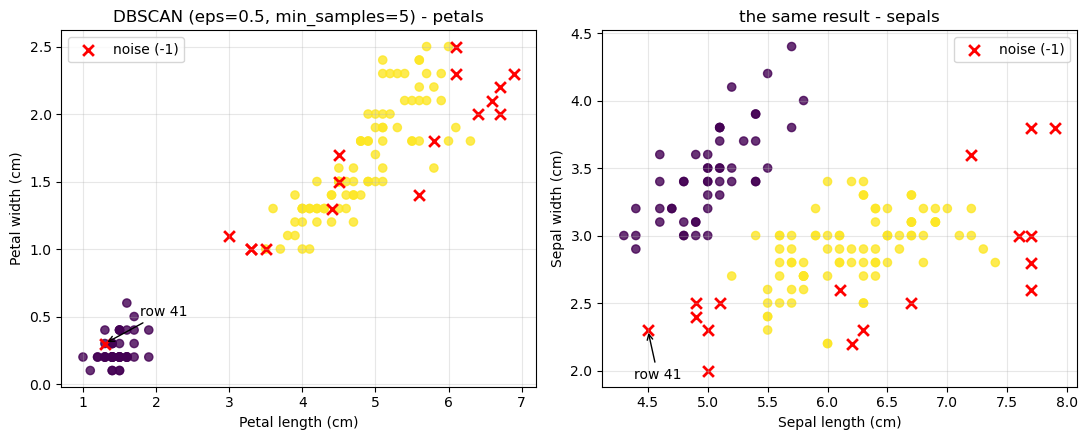

In [15]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X)

is_noise = dbscan_labels == -1
print('cluster sizes:', np.bincount(dbscan_labels[~is_noise]))
print('noise points :', is_noise.sum())

row = np.where(is_noise & (X[:, 2] < 2.5))[0][0]    # the noise point among the short petals
print('noise point among the short petals: row', row)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X[~is_noise, 2], X[~is_noise, 3], c=dbscan_labels[~is_noise], cmap='viridis', s=35, alpha=0.8)
axes[0].scatter(X[is_noise, 2], X[is_noise, 3], c='red', marker='x', s=60, linewidths=2, label='noise (-1)')
axes[0].set_xlabel('Petal length (cm)')
axes[0].set_ylabel('Petal width (cm)')
axes[0].set_title('DBSCAN (eps=0.5, min_samples=5) - petals')
axes[1].scatter(X[~is_noise, 0], X[~is_noise, 1], c=dbscan_labels[~is_noise], cmap='viridis', s=35, alpha=0.8)
axes[1].scatter(X[is_noise, 0], X[is_noise, 1], c='red', marker='x', s=60, linewidths=2, label='noise (-1)')
axes[1].set_xlabel('Sepal length (cm)')
axes[1].set_ylabel('Sepal width (cm)')
axes[1].set_title('the same result - sepals')
axes[0].annotate(f'row {row}', (X[row, 2], X[row, 3]), xytext=(25, 20), textcoords='offset points', arrowprops=dict(arrowstyle='->'))
axes[1].annotate(f'row {row}', (X[row, 0], X[row, 1]), xytext=(-10, -35), textcoords='offset points', arrowprops=dict(arrowstyle='->'))

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Sizes 49 / 84 and 17 noise points → the upper-right group stays one cluster
- It is one connected dense region → a density-based method does not split it

### A Noise Point inside the Lower-Left Group?

- On the petal axes row 41 sits among the dense lower-left group → check its four features and its nearest neighbour

In [16]:
distances = np.linalg.norm(X - X[row], axis=1)    # row 41 to every flower, all four features

print('row 41 features      :', X[row])
print('lower-left group mean:', X[dbscan_labels == 0].mean(axis=0).round(2))
print('nearest other flower :', np.sort(distances)[1].round(2))    # [0] is the flower itself, distance 0

row 41 features      : [4.5 2.3 1.3 0.3]
lower-left group mean: [5.02 3.45 1.47 0.24]
nearest other flower : 0.62


- Row 41: petals like the group (1.3, 0.3), but sepal width 2.3 against a group mean of 3.45 → far below the group on the sepal axes
- Nearest flower 0.62 away > `eps = 0.5` → no neighbour, so DBSCAN's rule marks it as noise, although it is a setosa

---
## Step 6. The Effect of DBSCAN — Non-convex Clusters

- K-means assigns each point to the nearest centre → straight boundaries, round clusters
- `make_moons` → two interleaved crescents with random jitter (`noise=0.1`); the true labels `y_moons` only colour the first plot
- `eps = 0.2` → below the smallest gap between the crescents (0.25), so the two never link; from `eps = 0.25` they merge into one cluster

DBSCAN found 2 clusters, 0 noise points


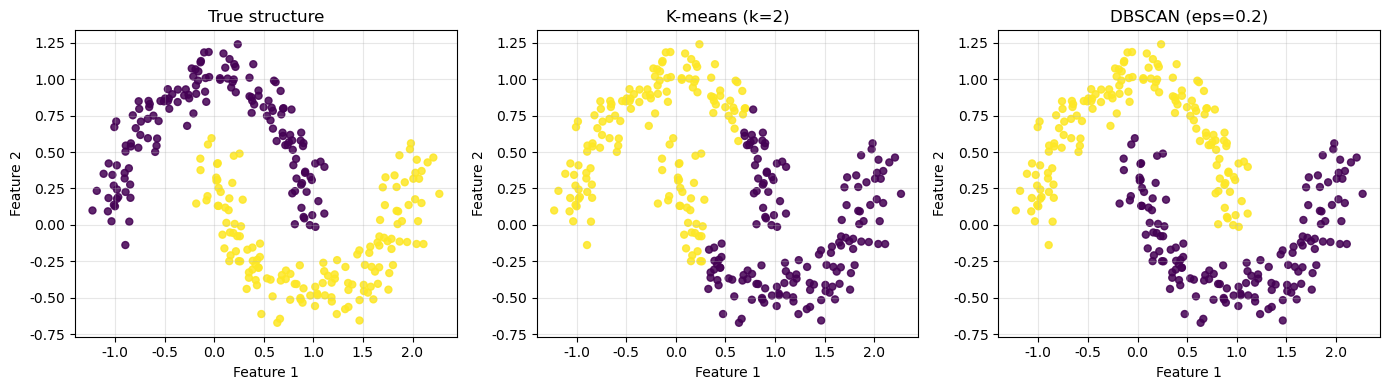

In [17]:
X_moons, y_moons = make_moons(n_samples=300, noise=0.1, random_state=42)

kmeans_moons = KMeans(n_clusters=2, n_init=10, random_state=42)
kmeans_labels_moons = kmeans_moons.fit_predict(X_moons)

dbscan_moons = DBSCAN(eps=0.2, min_samples=5)
dbscan_labels_moons = dbscan_moons.fit_predict(X_moons)

n_clusters = dbscan_labels_moons.max() + 1
n_noise = (dbscan_labels_moons == -1).sum()
print(f'DBSCAN found {n_clusters} clusters, {n_noise} noise points')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap='viridis', s=25, alpha=0.85)
axes[0].set_title('True structure')
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=kmeans_labels_moons, cmap='viridis', s=25, alpha=0.85)
axes[1].set_title('K-means (k=2)')
axes[2].scatter(X_moons[:, 0], X_moons[:, 1], c=dbscan_labels_moons, cmap='viridis', s=25, alpha=0.85)
axes[2].set_title('DBSCAN (eps=0.2)')

for ax in axes:
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- K-means → one straight line cuts across both crescents
- DBSCAN → each crescent is one connected dense region: 2 clusters, 0 noise points, the true crescents (colours swap only because cluster numbers are arbitrary)
- K-means suits round groups, DBSCAN connected shapes of any form → the shape of the data decides

---
## Step 7. Evaluating a Clustering — Silhouette

- No labels → a clustering has to be judged from `X` alone
- Score = mean of $s(i)$ over all samples; DBSCAN's noise label `-1` counts as one more cluster

### Iris

- `silhouette_samples` → $s(i)$ for every flower; colour each point by it (green = well placed, red = closer to another cluster)

Hierarchical (k=3) : 0.5543


K-means (k=3)      : 0.5528
DBSCAN (eps=0.5)   : 0.4860


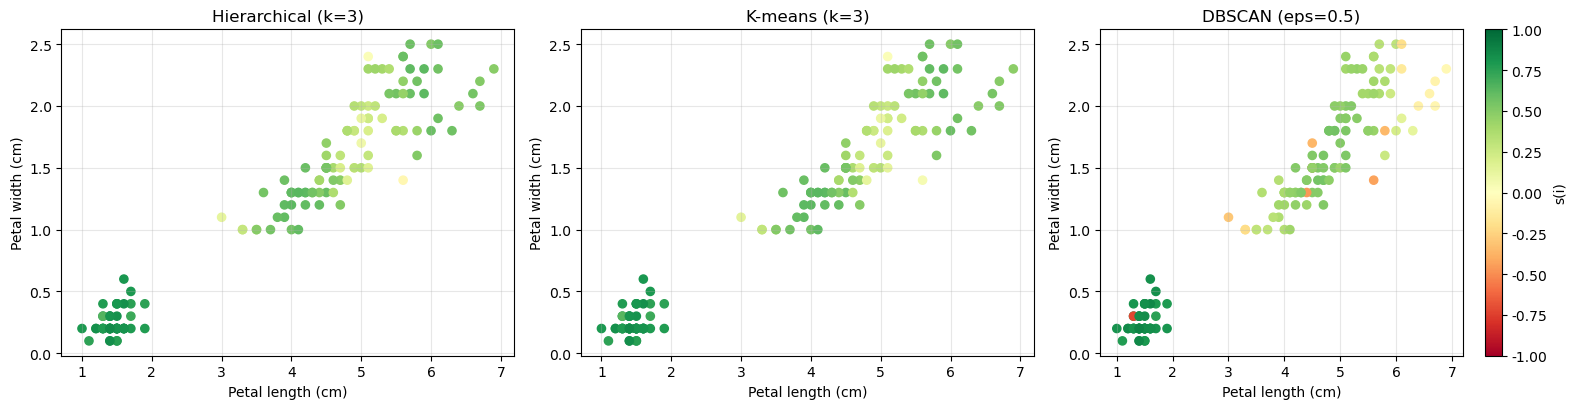

In [18]:
s_hierarchical = silhouette_samples(X, hierarchical_labels)
s_kmeans = silhouette_samples(X, kmeans_labels)
s_dbscan = silhouette_samples(X, dbscan_labels)

print(f'Hierarchical (k=3) : {silhouette_score(X, hierarchical_labels):.4f}')
print(f'K-means (k=3)      : {silhouette_score(X, kmeans_labels):.4f}')
print(f'DBSCAN (eps=0.5)   : {silhouette_score(X, dbscan_labels):.4f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].scatter(X[:, 2], X[:, 3], c=s_hierarchical, cmap='RdYlGn', vmin=-1, vmax=1, s=35)
axes[0].set_title('Hierarchical (k=3)')
axes[1].scatter(X[:, 2], X[:, 3], c=s_kmeans, cmap='RdYlGn', vmin=-1, vmax=1, s=35)
axes[1].set_title('K-means (k=3)')
points = axes[2].scatter(X[:, 2], X[:, 3], c=s_dbscan, cmap='RdYlGn', vmin=-1, vmax=1, s=35)
axes[2].set_title('DBSCAN (eps=0.5)')

for ax in axes:
    ax.set_xlabel('Petal length (cm)')
    ax.set_ylabel('Petal width (cm)')
    ax.grid(alpha=0.3)
fig.colorbar(points, ax=axes[2], label='s(i)')

plt.tight_layout()
plt.show()

- The score is the mean of these colours: hierarchical 0.55, K-means 0.55, DBSCAN 0.49
- Low $s(i)$ (pale yellow to red) sits where the upper-right group is cut in two, and on DBSCAN's noise points, which count as one scattered cluster

### Moons

K-means (k=2)    : 0.4795
DBSCAN (eps=0.2) : 0.3241


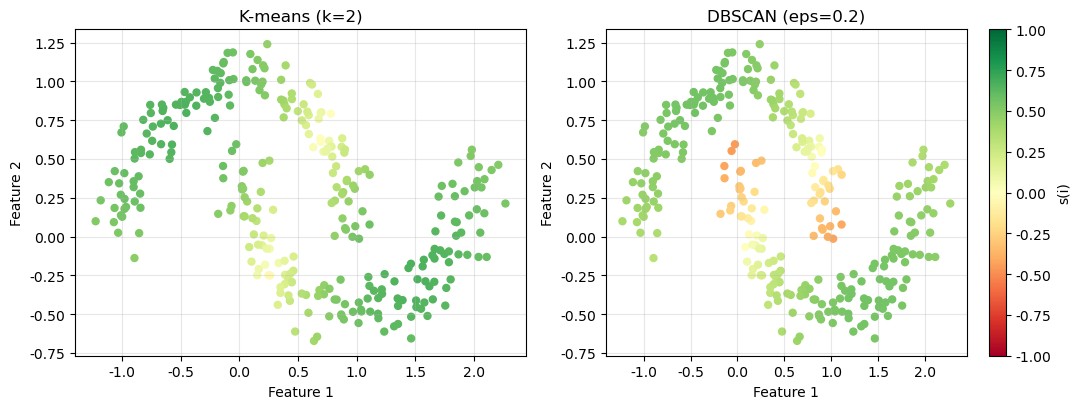

In [19]:
s_kmeans_moons = silhouette_samples(X_moons, kmeans_labels_moons)
s_dbscan_moons = silhouette_samples(X_moons, dbscan_labels_moons)

print(f'K-means (k=2)    : {silhouette_score(X_moons, kmeans_labels_moons):.4f}')
print(f'DBSCAN (eps=0.2) : {silhouette_score(X_moons, dbscan_labels_moons):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=s_kmeans_moons, cmap='RdYlGn', vmin=-1, vmax=1, s=25)
axes[0].set_title('K-means (k=2)')
points = axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=s_dbscan_moons, cmap='RdYlGn', vmin=-1, vmax=1, s=25)
axes[1].set_title('DBSCAN (eps=0.2)')

for ax in axes:
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.grid(alpha=0.3)
fig.colorbar(points, ax=axes[1], label='s(i)')

plt.tight_layout()
plt.show()

- K-means 0.48 > DBSCAN 0.32, though only DBSCAN found the two crescents
- DBSCAN: the inner tips of the crescents are orange, $s(i) < 0$ → their mean distance to the other crescent is smaller than to their own long crescent
- The silhouette rewards round, well-separated clusters → a high score does not mean the right clusters

---
## Step 8. PCA

- New data → `digits`: 1,797 images of 8 × 8 pixels = a `(1797, 64)` matrix
- Every pixel is an intensity from 0 to 16 → one unit for all 64 features, used as measured
- The digit label (0 to 9) → colours the plots only

X_digits: (1797, 64)


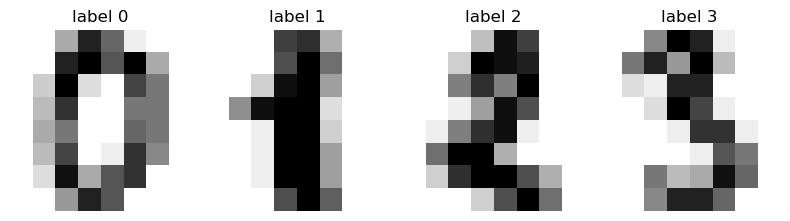

In [20]:
digits = load_digits()
X_digits = digits.data       # each row is one 8 x 8 image, flattened to 64 pixels
y_digits = digits.target     # used for colouring only

print(f'X_digits: {X_digits.shape}')

fig, axes = plt.subplots(1, 4, figsize=(8, 2.5))
for ax, image, label in zip(axes, digits.images, y_digits):
    ax.imshow(image, cmap='gray_r')
    ax.set_title(f'label {label}')
    ax.axis('off')
plt.tight_layout()
plt.show()

### Explained Variance

- PC 1 = direction of largest variance, PC 2 = the largest among directions orthogonal to PC 1, and so on
- Share of PC $i$, with $\lambda_i$ the eigenvalues of the covariance matrix and $p = 64$ features:

$$\text{explained variance ratio}_i = \frac{\lambda_i}{\lambda_1 + \cdots + \lambda_p}$$

- `PCA(n_components=0.95)` → keeps as many components as needed for 95%

PC 1, PC 2         : [0.1489 0.1362]
PC 1 + PC 2        : 0.2851
components for 95% : 29


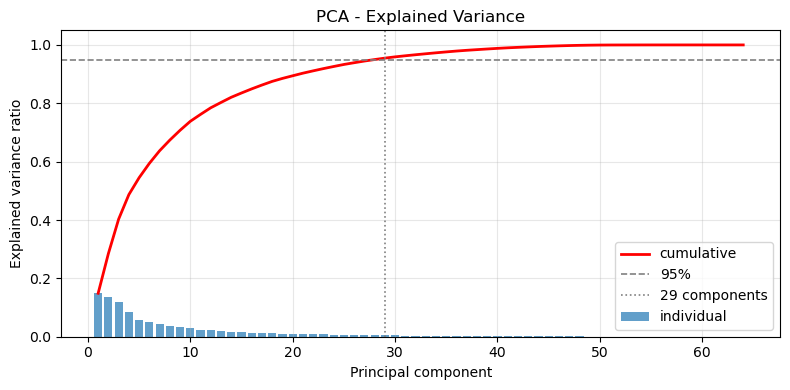

In [21]:
pca_full = PCA()
pca_full.fit(X_digits)
explained = pca_full.explained_variance_ratio_

pca_95 = PCA(n_components=0.95)
pca_95.fit(X_digits)

print('PC 1, PC 2         :', explained[:2].round(4))
print('PC 1 + PC 2        :', explained[:2].sum().round(4))
print('components for 95% :', pca_95.n_components_)

components = range(1, len(explained) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(components, explained, alpha=0.7, label='individual')
ax.plot(components, explained.cumsum(), 'r-', linewidth=2, label='cumulative')
ax.axhline(0.95, color='gray', linestyle='--', linewidth=1.2, label='95%')
ax.axvline(pca_95.n_components_, color='gray', linestyle=':', linewidth=1.2, label=f'{pca_95.n_components_} components')
ax.set_xlabel('Principal component')
ax.set_ylabel('Explained variance ratio')
ax.set_title('PCA - Explained Variance')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- PC 1 + PC 2 → 0.29 of the variance; 29 of the 64 components are needed for 95%
- A 2-D PCA plot therefore shows less than a third of the variation

### Projection onto PC 1 and PC 2

X_digits: (1797, 64) -> X_pca: (1797, 2)


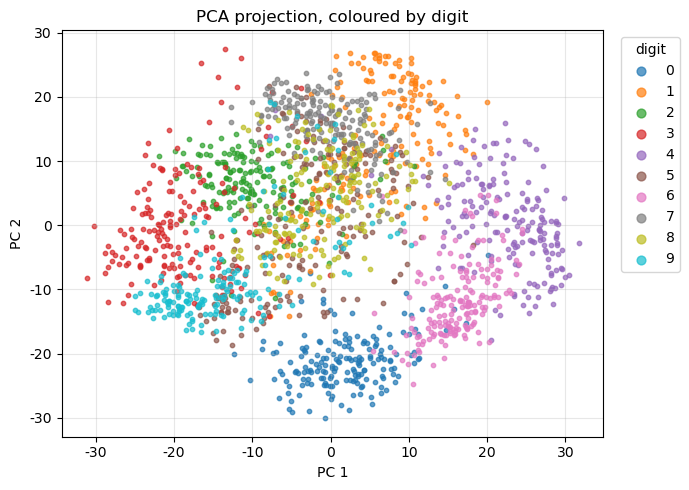

In [22]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_digits)

print(f'X_digits: {X_digits.shape} -> X_pca: {X_pca.shape}')

plt.figure(figsize=(7, 5))
for digit in range(10):
    is_digit = y_digits == digit
    plt.scatter(X_pca[is_digit, 0], X_pca[is_digit, 1], s=10, alpha=0.7, label=str(digit))
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title('PCA projection, coloured by digit')
plt.legend(title='digit', markerscale=2, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- 0, 4 and 6 are mostly apart; the other digits overlap each other in large part
- Two linear directions with 29% of the variance → not enough to separate ten digits

---
## Step 9. t-SNE

- Places the points in 2-D so that neighbours in the 64-D space stay neighbours
- `perplexity` (5 to 50) ≈ how many neighbours count
- Stochastic → fix `random_state`

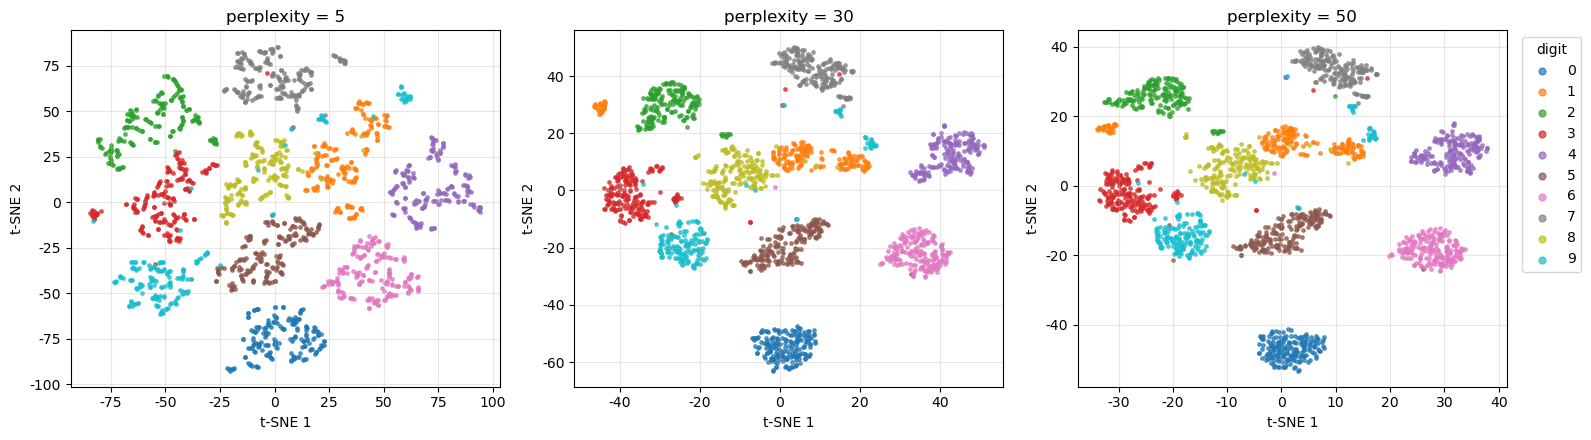

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, perplexity in zip(axes, [5, 30, 50]):
    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42, init='pca')
    X_tsne = tsne.fit_transform(X_digits)

    for digit in range(10):
        is_digit = y_digits == digit
        ax.scatter(X_tsne[is_digit, 0], X_tsne[is_digit, 1], s=6, alpha=0.7, label=str(digit))
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.set_title(f'perplexity = {perplexity}')
    ax.grid(alpha=0.3)

axes[2].legend(title='digit', markerscale=2, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

- `perplexity = 30` and `50` → most digits form one compact group; the 1s and 9s split into two or three pieces
- The digits that overlapped in PCA are now apart
- `perplexity = 5` → looser groups, broken into more fragments

### PCA vs. t-SNE

| | PCA | t-SNE |
|:---|:---|:---|
| Transformation | linear | non-linear |
| Fitted quantity | directions of maximum variance | neighbourhood relationships |
| New samples | `transform` works | must refit |
| Distances between groups | meaningful | not meaningful |
| Typical use | compression, preprocessing | visual inspection |

---
## Summary

| Method | Needs $k$ | Cluster shape assumed | Marks outliers |
|:---|:---|:---|:---|
| Hierarchical | no (cut height) | depends on the linkage | no |
| K-means | yes | round | no |
| DBSCAN | no (`eps`, `min_samples`) | any connected dense region | yes, as `-1` |

- Number of clusters → a choice: the elbow allows 2 or 3, the silhouette says 2
- Higher silhouette ≠ more correct → on the moons K-means outscored DBSCAN
- PCA keeps variance, t-SNE keeps neighbours → only t-SNE separated the digits